In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
import jinja2

In [2]:
df = pd.read_csv("headlights-incidents.csv", index_col=False)
df = df.drop(columns=["incidentId", "url"])
df["year"] = pd.to_numeric(df["year"])
print(f"Total Incidents: {len(df)}")
print(f"Year Range: {df['year'].min()} – {df['year'].max()}")
print(f"Number of Countries Represented: {df["country"].nunique()}")

Total Incidents: 284
Year Range: 1986 – 2026
Number of Countries Represented: 35


In [3]:
company_df = pd.read_csv("filtered_df.csv")
print(f"Number of unique companies: {company_df["company"].nunique()}")

Number of unique companies: 109


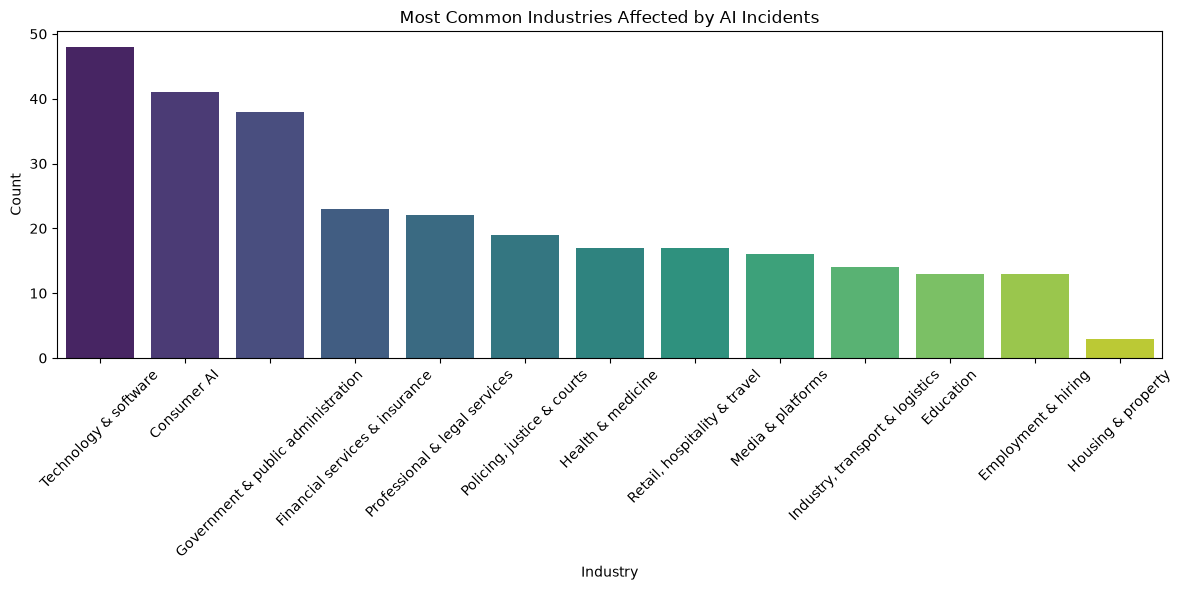

In [4]:
industry = (company_df["industry"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
    )
industry.columns = ["industry", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = industry,
    x = "industry",
    y = "count",
    hue = "industry",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Industries Affected by AI Incidents")
ax.set_xlabel("Industry")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

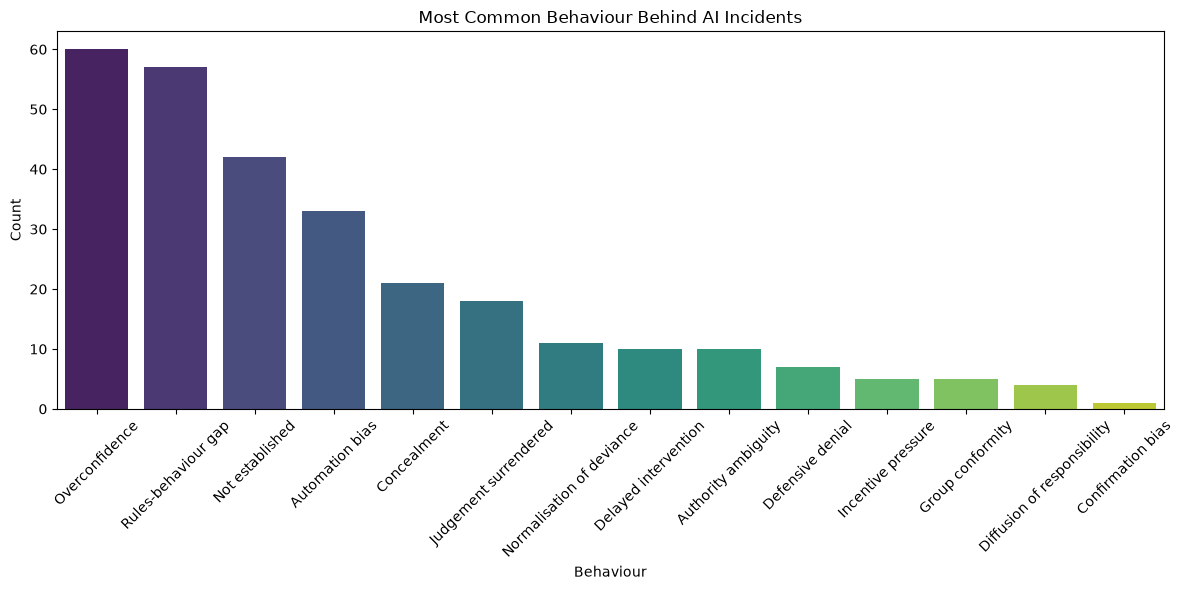

In [5]:
reasons = (company_df["behaviourPrimary"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
    )
reasons.columns = ["reason", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = reasons,
    x = "reason",
    y = "count",
    hue = "reason",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Behaviour Behind AI Incidents")
ax.set_xlabel("Behaviour")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

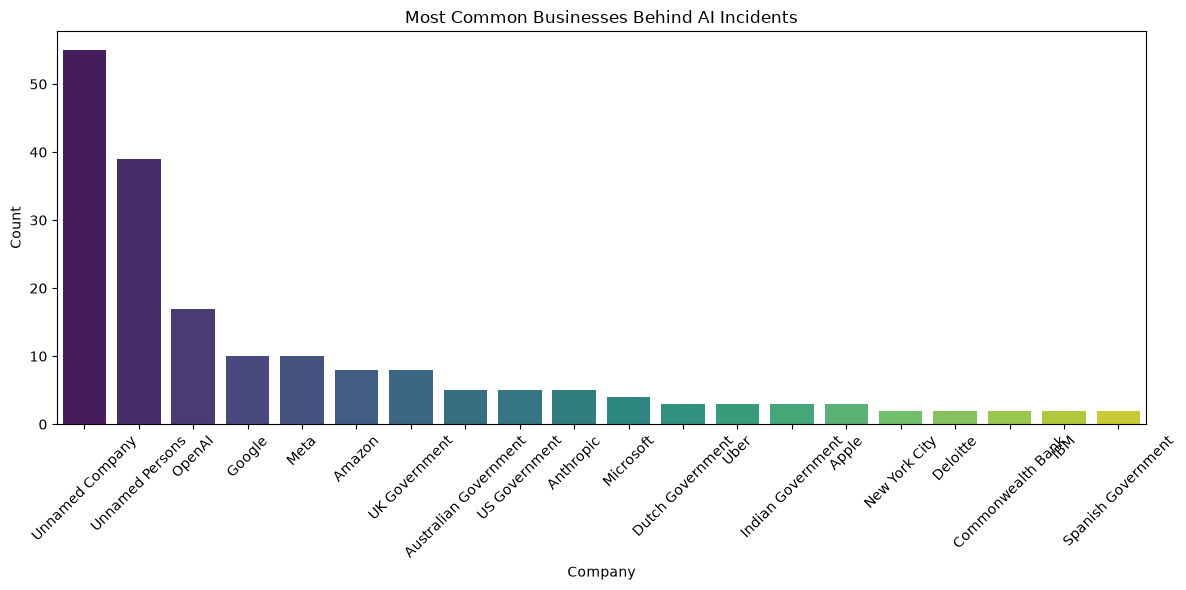

In [6]:
companies = (company_df["company"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
    )
companies.columns = ["company", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = companies,
    x = "company",
    y = "count",
    hue = "company",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Businesses Behind AI Incidents")
ax.set_xlabel("Company")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [7]:
countries = (company_df["country"]
    .value_counts()
    .head(20)
    .reset_index(name = "count")
)
print("Countries with the most incidents:")
print(countries)

Countries with the most incidents:
            country  count
0     United States    144
1         Australia     36
2    United Kingdom     22
3             Italy     10
4       Netherlands      7
5            Canada      6
6       South Korea      6
7            Brazil      6
8             India      4
9             Spain      4
10          Germany      4
11          Austria      3
12           France      3
13           Global      3
14     South Africa      3
15        Singapore      2
16          Ireland      2
17            Japan      2
18  Sweden / global      1
19        Hong Kong      1


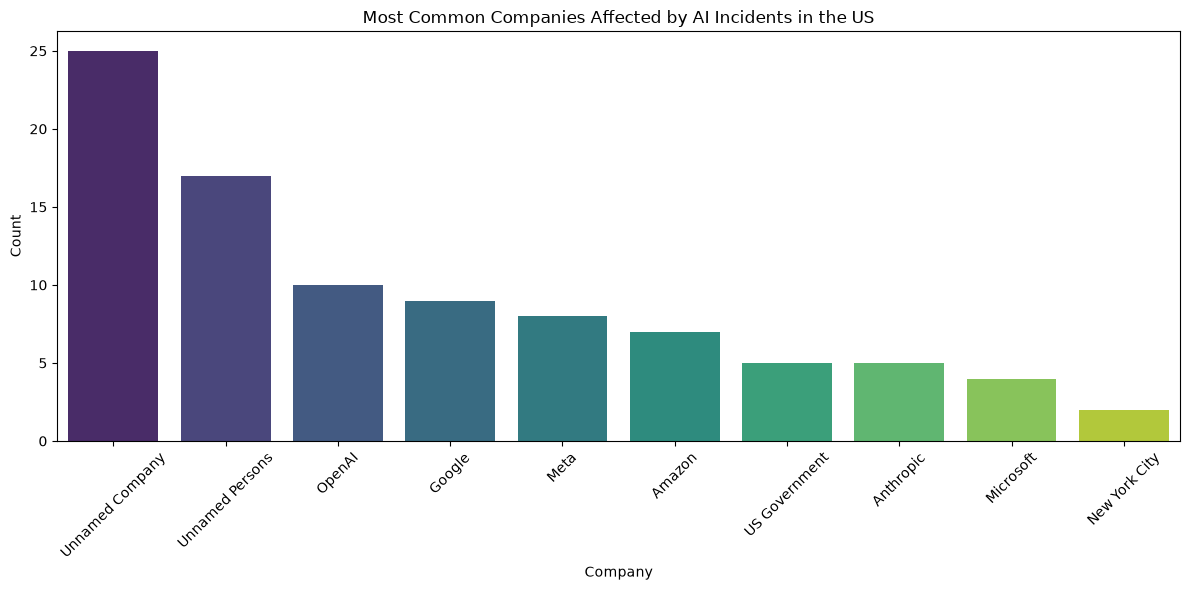

In [8]:
# Exploring just the US stats
us_data = company_df[company_df["country"] == "United States"]
us_company = (us_data["company"]
    .value_counts()
    .head(10)
    .reset_index(name="count")
    )
us_company.columns = ["company", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = us_company,
    x = "company",
    y = "count",
    hue = "company",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Companies Affected by AI Incidents in the US")
ax.set_xlabel("Company")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

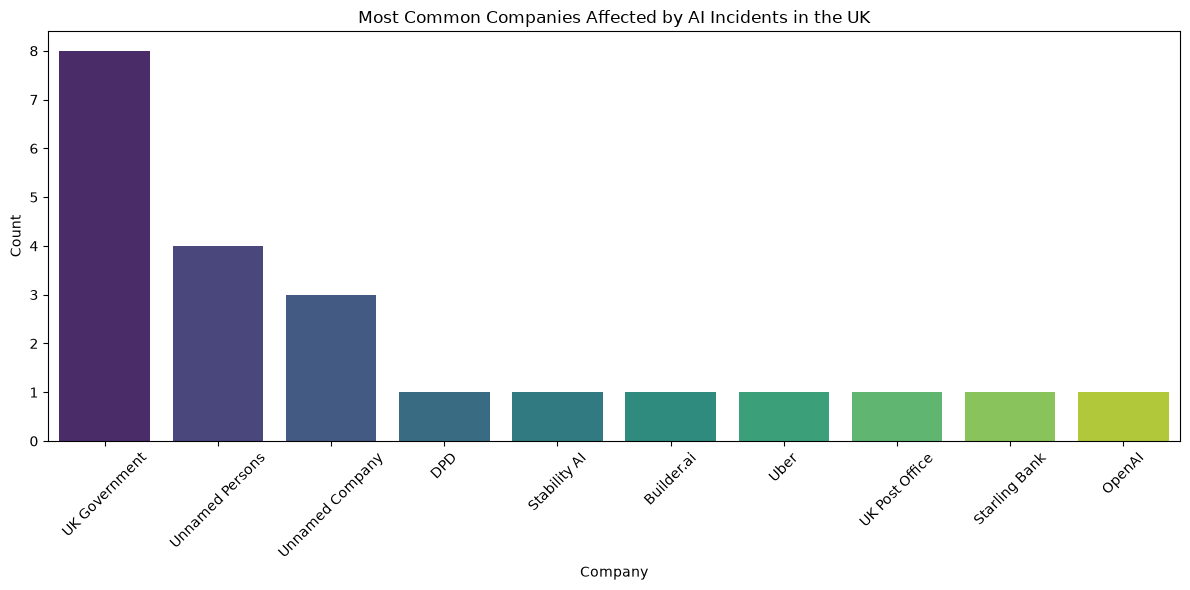

In [9]:
# Exploring just the UK stats
uk_data = company_df[company_df["country"] == "United Kingdom"]
uk_company = (uk_data["company"]
    .value_counts()
    .head(10)
    .reset_index(name="count")
    )
uk_company.columns = ["company", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = uk_company,
    x = "company",
    y = "count",
    hue = "company",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Companies Affected by AI Incidents in the UK")
ax.set_xlabel("Company")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

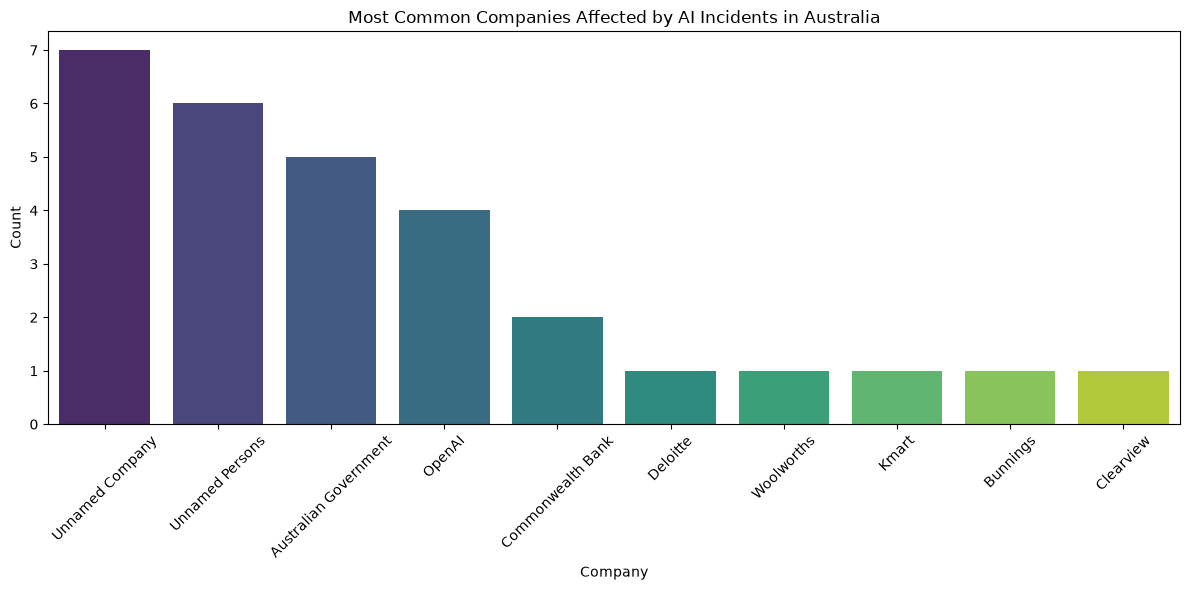

In [10]:
# Exploring just the Australian stats
aus_data = company_df[company_df["country"] == "Australia"]
aus_company = (aus_data["company"]
    .value_counts()
    .head(10)
    .reset_index(name="count")
    )
aus_company.columns = ["company", "count"]

fig, ax = plt.subplots(figsize = (12, 6))
sns.barplot(
    data = aus_company,
    x = "company",
    y = "count",
    hue = "company",
    palette = "viridis",
    legend = False
)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45)
ax.set_title("Most Common Companies Affected by AI Incidents in Australia")
ax.set_xlabel("Company")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

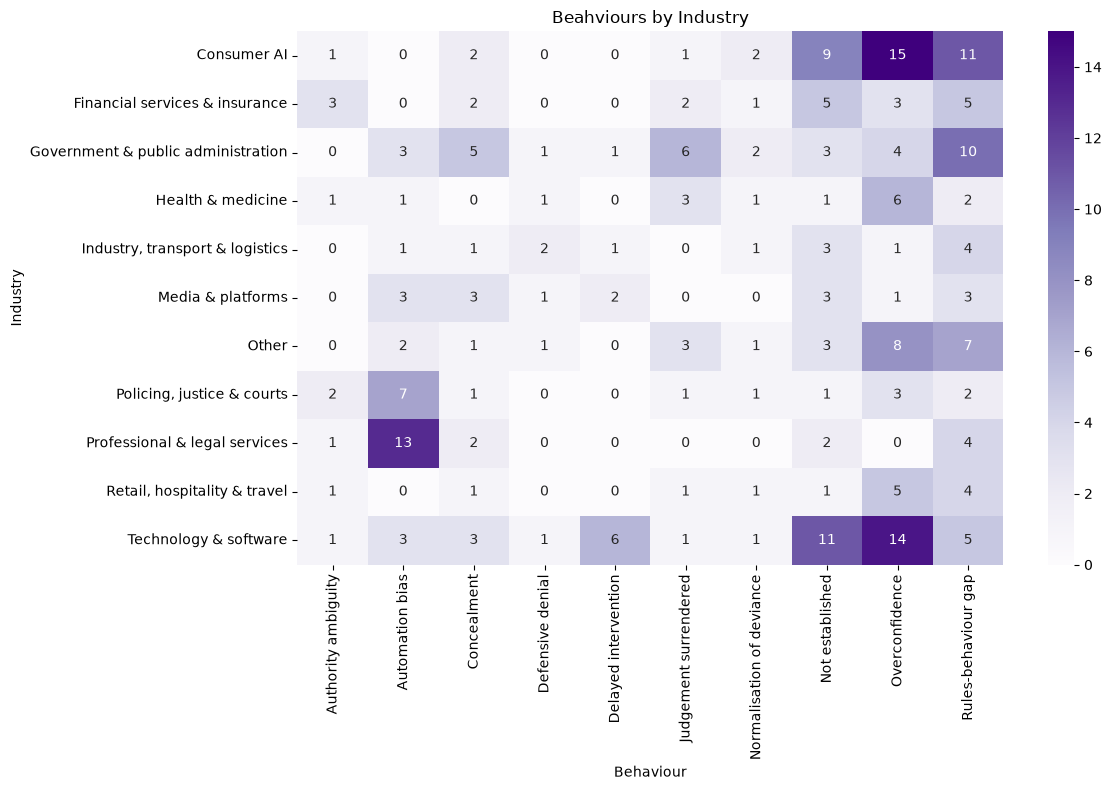

In [11]:
top_industries = company_df["industry"].value_counts().nlargest(10).index
company_df["industry_filtered"] = company_df["industry"].where(company_df['industry'].isin(top_industries), 'Other')

top_behav = company_df["behaviourPrimary"].value_counts().nlargest(10).index
sub = company_df[company_df['behaviourPrimary'].isin(top_behav)]

ct = pd.crosstab(sub['industry_filtered'], sub['behaviourPrimary'])
plt.figure(figsize = (12,8))
sns.heatmap(ct, annot=True, fmt='d', cmap='Purples')
plt.title("Beahviours by Industry")
plt.xlabel("Behaviour")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [16]:
common_style = {'description_width' : '110px'}
common_layout = widgets.Layout(width='400px', margin='4px 0')

company_dd = widgets.Dropdown(
    options=['(any)'] +
    sorted(company_df['company'].dropna().unique()),
    description='Company:',
    style=common_style,
    layout=common_layout
)
industry_dd = widgets.Dropdown(
    options=['(any)'] +
    sorted(company_df['industry'].dropna().unique()),
    description='Industry:',
    style=common_style,
    layout=common_layout
)
behaviour_dd = widgets.Dropdown(
    options=['(any)'] +
    sorted(company_df['behaviourPrimary'].dropna().unique()),
    description='AI Behaviour:',
    style=common_style,
    layout=common_layout
)

out = widgets.Output(layout={
    'border' : '1px solid #ddd',
    'padding' : '10px',
    'max_height' : '400px',
    'overflow' : 'auto'
})
count_label = widgets.HTML()

def on_change(change=None):
    out.clear_output()

    with out:
        m = pd.Series(True, index=company_df.index)

        if company_dd.value != '(any)':
            m &= company_df['company'] == company_dd.value

        if industry_dd.value != '(any)':
            m &= company_df['industry'] == industry_dd.value

        if behaviour_dd.value != '(any)':
            m &= company_df['behaviourPrimary'] == behaviour_dd.value

        result = company_df.loc[m, ['title', 'year', 'country']]

        if result.empty:
            count_label.value = "<h3 style='margin:4px 0'>0 matches</h3>"
            display("No matches found.")
        else:
            with pd.option_context('display.max_colwidth', None):
                shown = min(10, len(result))
                count_label.value = (
                f"<h3 style='margin:4px 0; color:#6d4aff;'>"
                f"Showing {shown} of {len(result)} matches</h3>")
                styled = (result.head(10)
                          .style
                          .hide(axis='index')
                          .format({'year' : '{:.0f}'})
                          .set_properties(**{'text-align' : 'left',
                                             'font-size' : '13px'})
                            .set_table_styles([{'selector': 'th',
                                                'props': 'background-color: #6d4aff; color: white; '
                                                'padding: 6px 10px; font-weight: 600;'},
                                                {'selector': 'td',
                                                 'props': 'padding: 6px 10px; border-bottom: 1px solid #eee;'},
                ]))
                display(styled)




company_dd.observe(on_change, names='value')
industry_dd.observe(on_change, names='value')
behaviour_dd.observe(on_change, names='value')

controls = widgets.HBox([company_dd, industry_dd, behaviour_dd])
display(controls, count_label, out)

on_change()

HTML(value='')

Output(layout=Layout(border_bottom='1px solid #ddd', border_left='1px solid #ddd', border_right='1px solid #dd…